In [1]:
import numpy as np

# 网格步长（米）
dx, dy, dz = 0.5, 0.5, 0.5

# 模型尺寸（米）
Lx, Ly, Lz = 30.0, 120.0, 30.0

# 计算网格点数（整数）
nx = int(Lx / dx)
ny = int(Ly / dy)
nz = int(Lz / dz)

# 构造速度模型（单位 km/s）
vp = np.ones((nx, ny, nz), dtype=np.float32) * 5000.0

# ========== 圆柱体隧道 ==========
# 原矩形范围：x 从 10/dx 到 20/dx，z 从 10/dz 到 20/dz，y 从 0 到 20/dy
# 使用网格索引计算中心
cx_idx = int((10/dx + 20/dx) / 2)   # 例如 15
cz_idx = int((10/dz + 20/dz) / 2)   # 例如 15
radius_idx = min((20-10)/dx, (20-10)/dz) / 2   # 取边长一半，约 5 网格单位

# Y 方向范围（与原矩形一致）
y_min_idx = 0
y_max_idx = int(20/dy)   # 例如 40

# 生成坐标网格（用于向量化掩码）
x = np.arange(nx).reshape(-1, 1, 1)   # (nx,1,1)
y = np.arange(ny).reshape(1, -1, 1)   # (1,ny,1)
z = np.arange(nz).reshape(1, 1, -1)   # (1,1,nz)

# 计算到圆柱轴（平行于 Y）的距离平方
dist2 = (x - cx_idx)**2 + (z - cz_idx)**2

# 构建掩码：在 Y 范围内且距离 ≤ 半径
mask = (y >= y_min_idx) & (y < y_max_idx) & (dist2 <= radius_idx**2)

# 赋值
vp[mask] = 0.001   # 隧道速度
vp_0 = vp.copy()
vp[:,120:160,:] = 3000

In [2]:
vp.shape

(60, 240, 60)

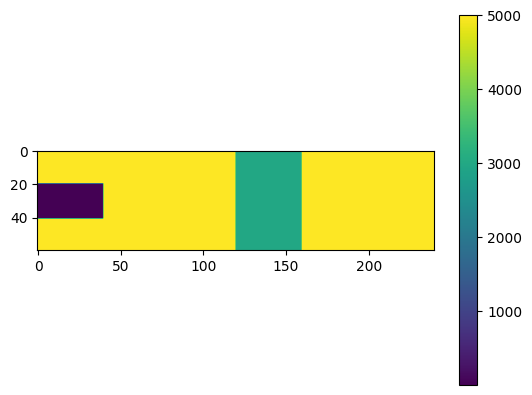

In [3]:
import matplotlib.pyplot as plt
plt.imshow(vp[:,:,30])
plt.colorbar()

In [4]:
import numpy as np

# -----------------------------
# source
# -----------------------------
source_list = [
    (8.0,18.0,15.0),
    (22.0,18.0,15.0)
]


# -----------------------------
# receivers
# -----------------------------

# 左侧检波器
receiver_left = np.array(
    [
        [8.0, y, 15.0]
        for y in np.linspace(13.0, 3.0, 6)
    ],
    dtype=np.float32,
)


# 右侧检波器
receiver_right = np.array(
    [
        [22.0, y, 15.0]
        for y in np.linspace(13.0, 3.0, 6)
    ],
    dtype=np.float32,
)


# 合并观测系统
receiver_xyz = np.vstack(
    (
        receiver_left,
        receiver_right,
    )
)


# print(source_xyz)

print(receiver_xyz)

[[ 8. 13. 15.]
 [ 8. 11. 15.]
 [ 8.  9. 15.]
 [ 8.  7. 15.]
 [ 8.  5. 15.]
 [ 8.  3. 15.]
 [22. 13. 15.]
 [22. 11. 15.]
 [22.  9. 15.]
 [22.  7. 15.]
 [22.  5. 15.]
 [22.  3. 15.]]


In [5]:
from acoustic3d_cpml_gpu import acoustic3d_cpml_gpu
from __future__ import annotations

from typing import Optional, Sequence, Tuple, Union

import numpy as np
import cupy as cp

import matplotlib.pyplot as plt


dt = 5.0e-5
nt = 1000
f0 = 200.0
n_pml = 40

seismic_records = []
seismic_records_k = [] #空模型的波场，用于去除直达波和隧道干扰

seismic_wavefields = []

seismic_snapshot_steps = []

for src in source_list:

    seismograms_gpu, wavefield_gpu,snapshot_steps = acoustic3d_cpml_gpu(
        vp=vp,
        dx=dx,
        dt=dt,
        nt=nt,
        f0=f0,
        snapshot_stride = 5,
        source_xyz=src,
        receiver_xyz=receiver_xyz,
        n_pml=n_pml,
        save_wavefield=True,  # True stores every padded 3-D pressure field on GPU.
    )

    seismograms_gpu_k, wavefield_gpu_k,snapshot_steps_k = acoustic3d_cpml_gpu(
        vp=vp_0,
        dx=dx,
        dt=dt,
        nt=nt,
        f0=f0,
        snapshot_stride = 5,
        source_xyz=src,
        receiver_xyz=receiver_xyz,
        n_pml=n_pml,
        save_wavefield=True,  # True stores every padded 3-D pressure field on GPU.
    )

    seismograms = cp.asnumpy(seismograms_gpu)
    seismograms_k = cp.asnumpy(seismograms_gpu_k)
    seismic_records.append(seismograms)
    seismic_records_k.append(seismograms_k)

    seismic_wavefields.append(wavefield_gpu)

    seismic_snapshot_steps.append(snapshot_steps)




In [6]:
len(seismic_records)

2

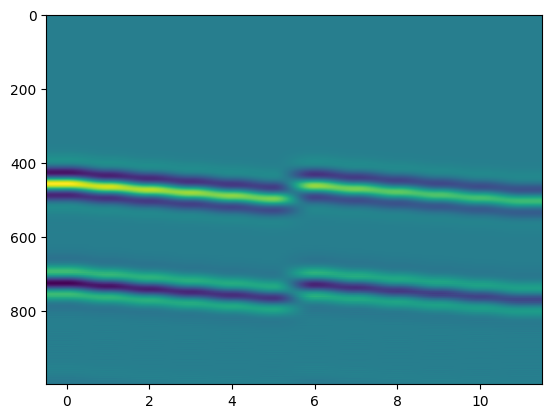

In [7]:
plt.imshow(seismic_records[0]-seismic_records_k[0],aspect="auto")

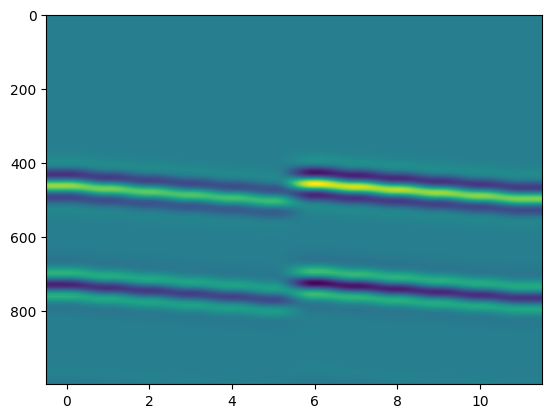

In [8]:
plt.imshow(seismic_records[1]-seismic_records_k[1],aspect="auto")

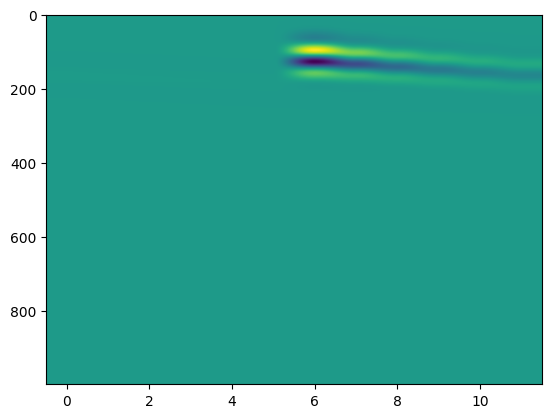

In [9]:
plt.imshow(seismic_records_k[1],aspect="auto")

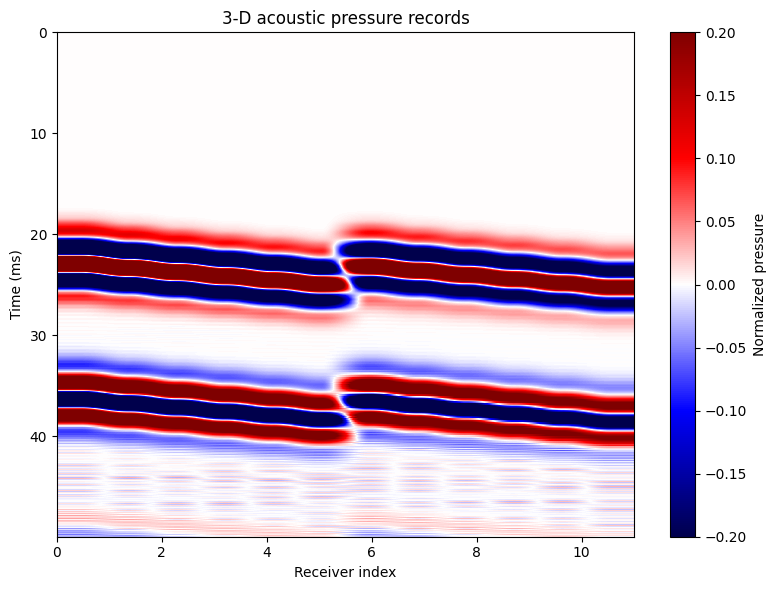

In [10]:
seismograms = cp.asnumpy(seismograms_gpu)
seismograms_k = cp.asnumpy(seismograms_gpu_k)
time_ms = np.arange(nt) * dt * 1.0e3

scale = np.max(np.abs(seismic_records[0]-seismic_records_k[0])) + 1.0e-12
plt.figure(figsize=(8, 6))
plt.imshow(
    (seismic_records[0]-seismic_records_k[0]) / scale,
    aspect="auto",
    cmap="seismic",
    extent=[0, 11, time_ms[-1], time_ms[0]],
    vmin=-0.2,
    vmax=0.2,
)
plt.xlabel("Receiver index")
plt.ylabel("Time (ms)")
plt.title("3-D acoustic pressure records")
plt.colorbar(label="Normalized pressure")
plt.tight_layout()
plt.show()

In [ ]:
from save_wavefield_video_2d import save_wavefield_video
save_wavefield_video(
    slice_wavefield_gpu=seismic_wavefields[0],
    snapshot_steps=seismic_snapshot_steps[0],
    dx=dx,
    dt=dt,
    output_path="/root/my_data/model_build/forward/Tunnel_yz_wavefield_1.mp4",
    slice_type="yz",
    # fps=10,
    n_pml=n_pml,
)

saved: /root/my_data/model_build/forward/Tunnel_yz_wavefield_1_test.mp4


In [37]:
save_wavefield_video(
    slice_wavefield_gpu=seismic_wavefields[1],
    snapshot_steps=seismic_snapshot_steps[1],
    dx=dx,
    dt=dt,
    output_path="/root/my_data/model_build/forward/Tunnel_yz_wavefield_2.mp4",
    slice_type="yz",
    # fps=10,
    n_pml=n_pml,
)

saved: /root/my_data/model_build/forward/Tunnel_yz_wavefield_2.mp4


In [12]:
wavefield = cp.asnumpy(seismic_wavefields[0])


In [13]:
wavefield.shape

(200, 320, 140)

In [18]:
%matplotlib inline
import matplotlib.pyplot as plt

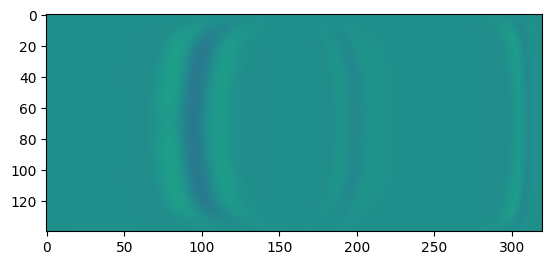

In [38]:
plt.imshow(wavefield[135,:,:].T,vmin=-0.0001,vmax=0.0001)
plt.show()